# Decoder stability under the ORIGINAL published configuration

A copy of `4_a_decoder_stability.ipynb` that answers one question:

> Do the local/global gene programs line up better with the published `TRUE_LOCAL_GENES` /
> `TRUE_GLOBAL_GENES` lists when the models are trained under the config that produced them
> (`legnini23_regr_node_DualCombined_genes.yaml`) **and** read out with the gene-selection
> settings of `Gene_loadings_analysis.ipynb`, rather than with 4_a's own settings?

Two axes are varied against 4_a, and they are independent:

| axis | 4_a (`MASKING="cell"`, sweep `ze40fzaz`) | here (sweep `lzefp69a`) |
|---|---|---|
| **training** | registry `legnini23/node_reg`, `n_epochs` **300** | the published yaml's settings, `n_epochs` **100** |
| **read-out** | `dims="all"` (16 dims), `n_top=3`, `min_frac=0`, no specificity | `cumulative_cutoff=0.60`, `n_top=20`, `min_frac=0.1`, `specificity_min=1.5` |

Masking is cell-wise (`mask_strategy="node"`, rate 0.30) on both sides, which is what the
published yaml's `pct_mask_nodes: 0.3` means -- that key was renamed to
`dataset.mask_percentage` in `ace2143`, the commit that also added `mask_strategy` and the
gene-wise alternative.

Section 5 applies both read-outs to the same five models, so the two axes are separable, and
section 5c crosses them against 4_a's own arm.

### Two things the yaml could not carry over

* **`optim.accelerator: cpu`** -- hardware, not a model setting. Left at `auto`, i.e. GPU, so the
  sweep takes minutes. Different RNG stream, so these are not bit-identical to a CPU run.
* **`MASK_VALUE`** -- `tl/masking.py` filled masked cells with `0` when the published models were
  trained and fills them with `-1` now. It is hardcoded, not a config key, so no yaml can restore
  it. This arm reproduces the published **configuration**, not the published **checkpoints**.
  Section 6 loads Sara's actual checkpoint, which does carry the old fill value, as the reference
  point.

In [1]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import issparse
import seaborn as sns
from scipy.sparse import csr_array, csr_matrix, issparse
import interscale

from pathlib import Path

import warnings
warnings.filterwarnings('ignore')

In [2]:
import os

# LRZ home
if os.path.exists("/dss/dsshome1/05/di93tig"):
    print('LRZ cluster')
    CLUSTER = 'LRZ'
    BASE_DIR_REPO = "/dss/dsshome1/05/di93tig/1_projects" 
    BASE_DIR_PROJECT = "/dss/dssfs03/tumdss/pn36po/pn36po-dss-0002/di93tig/Projects/A3_InterScale"
elif os.path.exists("/home/icb/francesca.drummer/"):
    print('HPC cluster')
    CLUSTER = 'HPC'
    BASE_DIR_REPO = "/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/"
    BASE_DIR_PROJECT = "/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/"
else:
    print('unkown')
    CLUSTER = 'unknown'
DATA = "legnini23"

HPC cluster


In [3]:
import yaml
with open(os.path.join(BASE_DIR_REPO, "figures/config.yml"), "r") as f:
    config = yaml.safe_load(f)

PALETTE = config["palettes"]["continuous"]
#CELL_TYPE_COLORS = config["palettes"][DATA]

slides = config["slide_examples"]["legnini23"]

<mark>TODO: Change data path</mark>

In [4]:
LRZ_LEGNINI23 = f'{BASE_DIR_PROJECT}/data/{DATA}.h5ad'  

## Load data

In [5]:
adata = sc.read_h5ad(LRZ_LEGNINI23)
adata

AnnData object with n_obs × n_vars = 43762 × 88
    obs: 'Cell', 'Area', 'x', 'y', 'sample', 'condition', 'organoid', 'obs_names', 'split'
    var: 'gene_ids', 'feature_types'
    obsm: 'spatial'
    layers: 'log1p_norm', 'norm_ftsqrt', 'raw', None (.X)

In [6]:
print('Zero count cells: ', (adata.X.sum(1) ==0).sum())

Zero count cells:  648


In [7]:
# only needed when re-running on an adata that already carries the zones
adata.obs.drop(columns=["SHH_zone"], errors="ignore", inplace=True)

In [8]:
from interscale.tl import clustering

# The last edge is open-ended on purpose. create_spatial_cluster_distance bins
# dist_to_SHH with pd.cut, so any cell beyond the last edge becomes NaN in
# SHH_zone. With a closed edge at 6000 that silently dropped 685 cells of
# slide1_C2-2 (dist_to_SHH 6000-8034, the only slide reaching that far), and the
# NaN propagated into sliding_window_low -> scvi's CategoricalObsField assigns
# code -1 and register_fields dies with
#   ValueError: Making .obs["sliding_window_low"] categorical failed.
# np.inf puts that tail into 'far', where it belongs, and keeps 4 rings.
ring_edges  = [0, 200, 2000, 3000, np.inf]
ring_labels = ['SHH', 'near', 'medium', 'far']

clustering.create_spatial_cluster_distance(
    adata, 'SHH', 'sample',
    distance_bins=ring_edges,
    bin_labels=ring_labels,
    threshold=95,
)

AnnData object with n_obs × n_vars = 43762 × 88
    obs: 'Cell', 'Area', 'x', 'y', 'sample', 'condition', 'organoid', 'obs_names', 'split', 'dist_to_SHH', 'SHH_zone'
    var: 'gene_ids', 'feature_types'
    obsm: 'spatial'
    layers: 'log1p_norm', 'norm_ftsqrt', 'raw', None (.X)

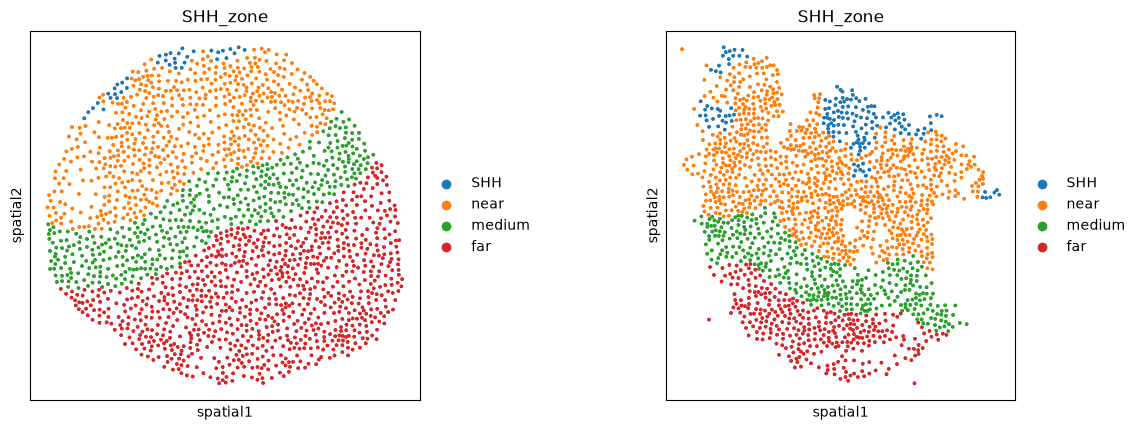

In [9]:
sq.pl.spatial_scatter(
    adata[adata.obs['sample'].isin([slides["Ctrl"], slides["SSH"]])],
    spatial_key = 'spatial',
    library_key='sample', 
    #library_id = [839, 6],
    color="SHH_zone", #cell_type_coarse",
    shape= None,
    size = 10,
)

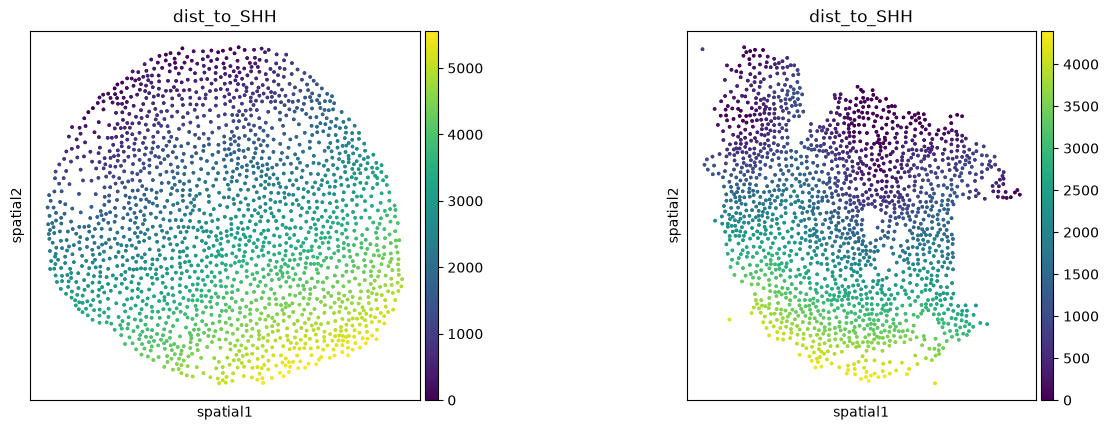

In [10]:
sq.pl.spatial_scatter(
    adata[adata.obs['sample'].isin([slides["Ctrl"], slides["SSH"]])],
    spatial_key = 'spatial',
    library_key='sample', 
    #library_id = [839, 6],
    color="dist_to_SHH", #cell_type_coarse",
    shape= None,
    size = 10,
)

Check that no NaN's exists in the data.

In [11]:
# dropna=False: a plain groupby().size() hides exactly the NaNs this checks for
print(adata.obs["SHH_zone"].value_counts(dropna=False))
assert adata.obs["SHH_zone"].isna().sum() == 0, (
    "cells outside every ring - widen ring_edges (the last edge must cover max(dist_to_SHH))"
)

SHH_zone
near          25023
medium         9043
far            8110
SHH            1586
No_Source         0
Background        0
Name: count, dtype: int64


## Load trained models

In [12]:
import sys

project_root = Path(BASE_DIR_REPO)  # InterScale_reproducibility, for `from src.wandb import ...`
sys.path.insert(0, str(project_root))

# The interscale package is a SIBLING of InterScale_reproducibility, not a subdirectory of it.
INTERSCALE_REPO = project_root.parent / "interscale"
REGISTRY = INTERSCALE_REPO / "config_files" / "registry.yaml"

DATASET = "legnini23"

# ---------------------------------------------------------------------------------------------
# THE ARM. Unlike 4_a there is no MASKING switch: masking is cell-wise here, full stop, because
# that is what the published yaml's `pct_mask_nodes: 0.3` means. What is varied in this notebook
# is the gene-selection read-out (section 5), not the training condition.
#
# sweep lzefp69a  <- config_files/sweeps/seed_sara_cfg_legnini.yaml
#   five seeds under the settings of
#   /lustre/groups/ml01/workspace/sara.jimenez/InterScale/configs/legnini23_regr_node_DualCombined_genes.yaml
#
# The matched control is 4_a's own cell arm, sweep ze40fzaz -- same masking, same architecture,
# same five seeds, but n_epochs 300 instead of the published 100.
# ---------------------------------------------------------------------------------------------
TASK = "node_reg"
SWEEP_ID = "lzefp69a"
MODELS_DIR = Path(BASE_DIR_PROJECT) / "results" / "legnini23_revision" / "seed_stability_sara_cfg"
RESULTS_DIR = Path(BASE_DIR_PROJECT) / "results" / DATA / "rec_seed_stablity_sara_cfg"

# Every scalar legnini23_regr_node_DualCombined_genes.yaml states, reapplied on top of the
# resolved (DATASET, TASK) pair -- the same list the sweep yaml pins, so the config reconstructed
# here IS the config each trial trained with. Written out rather than trusted to the registry:
# the registry happens to agree on all but n_epochs today, and a pin is the difference between
# "agrees today" and "is the stated condition".
#
# n_epochs 100 is the one that actually differs from 4_a's 300, and it is not a small difference:
# 100 -> 300 moves val_concordance_corr by +200% to +286% on this dataset. The published config
# sets no n_epochs, so it took the schema default of 100; that default is the published condition
# and undertraining is part of what this notebook is measuring.
SARA_CFG = {
    "optim.n_epochs": 100,
    "optim.lr": 0.001,
    "optim.loss": "SmoothL1",
    "model.n_embed": 16,
    "model.decoder.type": "linear",
    "model.decoder.dual_decoder": True,
    "dataset.batch_size": 3,
    "dataset.layer_key": "log1p_norm",
    "dataset.mask_strategy": "node",     # cell-wise; the only behaviour pct_mask_nodes had
    "dataset.mask_percentage": 0.3,      # pct_mask_nodes: 0.3
    "dataset.spatial_neigbors_kwargs.radius": 200,
    # 4299, the yaml's value, not the registry's 4318. Both are >= the largest graph after
    # remove_zero_expression_cells (slide1_D2-2: 4318 raw, 4299 filtered), so no graph is ever
    # subsampled by pad_batch either way, and max_seq_len is padding only -- no parameter has
    # that shape, so it does not change checkpoint shapes.
    "model.global_component.parameters.max_seq_len": 4299,
}

assert REGISTRY.exists(), f"registry not found: {REGISTRY}"
assert MODELS_DIR.exists(), (
    f"checkpoint dir not found: {MODELS_DIR}\n"
    f"Train it with:  SWEEP_ID={SWEEP_ID} sbatch scripts/run.sh {DATASET} {TASK} "
    f"--sweep_cfg config_files/sweeps/seed_sara_cfg_legnini.yaml --sweep_goal robustness --count 5"
)
print(f"sweep       {SWEEP_ID} (task {TASK}, cell masking at {SARA_CFG['dataset.mask_percentage']})")
print(f"registry    {REGISTRY}\ncheckpoints {MODELS_DIR}\nresults     {RESULTS_DIR}")

sweep       lzefp69a (task node_reg, cell masking at 0.3)
registry    /home/icb/francesca.drummer/1-Projects/A3_InterScale/interscale/config_files/registry.yaml
checkpoints /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/legnini23_revision/seed_stability_sara_cfg
results     /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/legnini23/rec_seed_stablity_sara_cfg


In [13]:
import os
from pathlib import Path

import wandb

from interscale.evaluation import gene_loadings, get_genes_dim, calculate_dim_importance
from interscale.tl.utils import set_full_reproducibility
from src.wandb import Wandb_evaluation

from src.decoder_stability import (
    GROUP_COLORS,
    build_cfg as _build_cfg,
    collect_gene_sets,
    expected_intersection,
    intersection_by_k,
    intersection_tail_probability,
    local_global_split,
    overlap_matrix,
    plot_intersection_by_k,
    plot_membership,
    plot_tail_prob_by_k,
    run_seed_inference,
)

wandb.login()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/icb/francesca.drummer/.netrc.


wandb: Currently logged in as: francesca-drummer to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

## 2. The sweep

In [14]:
# NOT `wandb = ...`: that name is the wandb module, imported above, and rebinding it is what
# made `wandb.Api(timeout=60)` raise AttributeError. The first argument is only a label --
# Wandb_evaluation hardcodes entity/project to
# francesca-drummer/InterScale_hyperparameter_sweep.
sweep_eval = Wandb_evaluation(
    "InterScale",
    SWEEP_ID,
    local_component=True,
    global_component=True,
    sweep_goal="robustness",
    classes=[None],
)
sweep_df = sweep_eval.get_dataframe()
sweep_df.head()

,id,name,seed,state,mask_percentage,mask_strategy,pct_mask_nodes,radius,decoder_type,runtime_seconds,total_parameters,test_r2,test_pearson_corr
0,1nmw91p2,dual_legnini23_regr_node_40_GCN_self-attn-tran...,40,finished,0.3,node,0.3,200,linear,99,51168,-17.512787,0.064007
1,uj7boqfy,dual_legnini23_regr_node_41_GCN_self-attn-tran...,41,finished,0.3,node,0.3,200,linear,93,51168,-15.691265,0.046763
2,9jsohq60,dual_legnini23_regr_node_42_GCN_self-attn-tran...,42,finished,0.3,node,0.3,200,linear,98,51168,-21.788797,0.047541
3,s97bskzx,dual_legnini23_regr_node_43_GCN_self-attn-tran...,43,finished,0.3,node,0.3,200,linear,102,51168,-22.352304,0.053481
4,4sbhmcbx,dual_legnini23_regr_node_44_GCN_self-attn-tran...,44,finished,0.3,node,0.3,200,linear,99,51168,-14.170445,0.050253


In [15]:
from functools import partial

# optim.seed is not cosmetic: get_model_filename_prefix puts it in the checkpoint name, which is
# what makes the five models separable when load() picks the file.
#
# THE SEED CANNOT BE READ OFF run.config['optim']['seed']. main_sweep.py calls
# wandb.init(config=cfg) BEFORE apply_sweep_config, so the nested config wandb stored is the base
# config -- seed 44 for all five runs, which is also why every run is named `..._44_...`. Only the
# flattened run.config['optim.seed'] (what sweep_df["seed"] reads) carries the trial's value.
build_cfg = partial(
    _build_cfg,
    DATASET,
    TASK,
    REGISTRY,
    models_dir=MODELS_DIR,
    overrides=SARA_CFG,
)

## 3. Model inference

In [16]:
from interscale.tl import remove_zero_expression_cells

# Training ran on the zero-expression-filtered adata (43762 -> 43114 cells). Inference has to
# filter identically, or the per-sample graphs handed to the model are not the graphs it saw.
#
# remove_zero_expression_cells reads adata.X, and a cell further down repoints adata.X at
# log1p_norm -- where no cell sums to zero -- so restoring layers['raw'] first makes this cell
# order-independent.
adata.X = adata.layers["raw"]
adata = remove_zero_expression_cells(adata)

SEEDS = sorted(sweep_df["seed"].astype(int))
print("seeds:", SEEDS)

cfg0 = build_cfg(SEEDS[0])
window_key = cfg0.dataset.sample_key[0]
assert cfg0.model.decoder.dual_decoder, (
    "cfg has no local decoder, so there is nothing to compare against the global one"
)

# Below max_seq_len, tl/padding.py random-subsamples each graph every call instead of erroring,
# so the predictions would come from a graph the model never saw. 4299 is exactly the largest
# filtered graph, so this asserts equality in practice -- if it ever fires, the zero-cell filter
# above did not run.
sizes = adata.obs[window_key].value_counts()
sizes = sizes[sizes > 0]
assert sizes.max() <= cfg0.model.global_component.parameters.max_seq_len, (
    f"largest {window_key} graph is {sizes.max()} cells but max_seq_len is "
    f"{cfg0.model.global_component.parameters.max_seq_len}"
)
print(f"{len(sizes)} graphs over '{window_key}', largest {sizes.max()} cells "
      f"(max_seq_len {cfg0.model.global_component.parameters.max_seq_len})")

# Ground truth is the layer the decoders were trained to reconstruct, NOT .X -- this h5ad keeps
# counts in X (max 279) against log1p-scale predictions (max ~5.6).
_y_true = adata.layers[cfg0.dataset.layer_key]
y_true = np.asarray(_y_true.todense() if issparse(_y_true) else _y_true, dtype=np.float64)
LAYER_KEY = cfg0.dataset.layer_key

Nr. of zero expression cells: 648
seeds: [40, 41, 42, 43, 44]
17 graphs over 'sample', largest 4299 cells (max_seq_len 4299)


In [17]:
# Writes obsm[f"{seed}_local_emb"] / obsm[f"{seed}_global_emb"] and
# layers[f"{seed}_y_pred_local"] / layers[f"{seed}_y_pred_global"] into adata, plus one per-gene
# csv per seed under RESULTS_DIR. The seed prefix is what lets the read-out section below revisit
# any seed, not only the last one inferred.
adata, models, local_emb, global_emb, performance = run_seed_inference(
    adata,
    SEEDS,
    build_cfg,
    MODELS_DIR,
    RESULTS_DIR,
    y_true=y_true,
    repro_seed=40,   # nothing stochastic happens between load and forward pass
)

Loading model from /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/legnini23_revision/seed_stability_sara_cfg/dual_legnini23_regr_node_40_GCN_self-attn-transformer_model.pt
Unclear checkpoint format. Attempting remapping anyway.
State dict remapping applied. Source detected: unknown
Load GEX from .layers/log1p_norm
INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


...

INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  



seed 44: wrote model_44_performance.csv (704 rows)
  per-gene medians on the test split:
               r2       mse   pearson  cosine_sim
decoder                                          
global  -1.172862  0.372479  0.022208    0.367955
local   -2.255894  0.485744  0.057451    0.197912

embeddings: local (43114, 16), global (43114, 16) per seed


In [18]:
# How far short of 4_a's 300-epoch arm this one trains. Reconstruction quality is not the
# question here, but it bounds how much the loadings can be worth reading -- so it is stated
# rather than left implicit.
summary = (
    pd.concat({s: performance[s] for s in SEEDS}, names=["seed"])
    .reset_index(level=0)
    .query("split == 'test'")
    .groupby(["seed", "decoder"])[["r2", "pearson", "cosine_sim"]]
    .median()
)
print(summary.to_string())
# Wandb_evaluation only pulls test_* into the frame, so the sweep's own numbers come from
# run.summary directly -- val_concordance_corr is the metric the 100-vs-300-epoch comparison
# was made on and it is not a column here.
_api = wandb.Api(timeout=60)
_sweep = _api.sweep(f"francesca-drummer/InterScale_hyperparameter_sweep/{SWEEP_ID}")
print("\n" + pd.DataFrame([
    {"seed": r.config.get("optim.seed"), "epochs": r.config.get("optim.n_epochs"),
     "val_r2": r.summary.get("val_r2"),
     "val_concordance_corr": r.summary.get("val_concordance_corr"),
     "epoch_stopped": r.summary.get("epoch"), "runtime_s": r.summary.get("_runtime")}
    for r in _sweep.runs
]).sort_values("seed").to_string(index=False))

                    r2   pearson  cosine_sim
seed decoder                                
40   global  -1.415851  0.024523    0.380708
     local   -2.527571  0.053385    0.304719
41   global  -2.560980  0.004279    0.162068
     local   -2.151409  0.067591    0.125430
42   global  -1.523930  0.032465    0.263103
     local   -3.202397  0.010702    0.127825
43   global  -0.793780  0.028742    0.382837
     local   -3.690832  0.085111    0.088944
44   global  -1.172862  0.022208    0.367955
     local   -2.255894  0.057451    0.197912



 seed  epochs     val_r2  val_concordance_corr  epoch_stopped  runtime_s
   40     100  -7.974041              0.019978            100         99
   41     100  -6.578319              0.014041            100         93
   42     100  -9.134957              0.013435            100         98
   43     100 -10.885530              0.022918            100        102
   44     100  -6.780205              0.026834            100         99


## 4. The published gene lists

In [19]:
# The published lists, verbatim from 4_a_decoder_stability.ipynb. These are what "more overlap"
# is measured against.
TRUE_LOCAL_GENES = ['DBX2', 'AGO2', 'CUX2', 'FOS', 'GLI1', 'PAX6', 'TUBB3', 'SATB2', 'DBX1', 'NKX6.1', 'ISL1', 'JUNB']
TRUE_GLOBAL_GENES = ["AC129492.1", "TBP", "VAMP2", "FOXO6", "NEUROD1", "NEUROG2", "OLIG2", "PAX7", "DBX1", "HHIP", "PER3", "POLR1B", "PROM1", "ZNF609"]

# Gene_loadings_analysis.ipynb's own final picks are a strict subset of each list, which is what
# makes the two lists the right target for that notebook's settings:
#   local  ['CUX2','GLI1','TUBB3','ISL1']   global ['FOXO6','NEUROG2','HHIP','PROM1']
PUBLISHED_LOCAL_PICKS = ['CUX2', 'GLI1', 'TUBB3', 'ISL1']
PUBLISHED_GLOBAL_PICKS = ['FOXO6', 'NEUROG2', 'HHIP', 'PROM1']

TRUE = {"local": TRUE_LOCAL_GENES, "global": TRUE_GLOBAL_GENES}
for which, genes in TRUE.items():
    missing = [g for g in genes if g not in set(adata.var_names)]
    assert not missing, f"{which} truth list names genes not in the panel: {missing}"
assert set(PUBLISHED_LOCAL_PICKS) <= set(TRUE_LOCAL_GENES)
assert set(PUBLISHED_GLOBAL_PICKS) <= set(TRUE_GLOBAL_GENES)
print(f"{len(TRUE_LOCAL_GENES)} true local, {len(TRUE_GLOBAL_GENES)} true global, "
      f"{len(set(TRUE_LOCAL_GENES) & set(TRUE_GLOBAL_GENES))} in both "
      f"({sorted(set(TRUE_LOCAL_GENES) & set(TRUE_GLOBAL_GENES))}) out of {adata.n_vars} genes")

12 true local, 14 true global, 1 in both (['DBX1']) out of 88 genes


## 5. Two read-outs of the same five models

In [20]:
# ---------------------------------------------------------------------------------------------
# The two read-outs, applied to the SAME five models. Nothing about the models changes between
# them; only which dimensions are scored and how strictly genes are filtered.
#
#   "4a"         what 4_a_decoder_stability.ipynb does. Every one of the 16 dimensions is
#                scored, three genes each, no expression floor and no specificity requirement.
#                On an 88-gene panel that is a wide net: up to 48 genes, >half the panel.
#
#   "published"  Gene_loadings_analysis.ipynb's settings, verbatim where they transfer:
#                  n_top=20, X_layer="log1p_norm", min_frac=0.1, rank_by="loading_x_sd",
#                  enforce_specificity=True, specificity_min=1.5
#                One thing does NOT transfer literally. That notebook pins its dimensions by
#                hand -- global [11,1,7,5,10], local [13,14,1,0,7,2] -- read off a
#                pl_dim_importance_elbow_stdexpr plot drawn at cumulative_cutoff=0.60. A latent
#                dimension index is arbitrary and carries no meaning across seeds, so pinning
#                those same integers on five fresh models would select five unrelated things.
#                cumulative_cutoff=0.60 IS the procedure those integers came out of, so it is
#                what transfers. How many dims it leaves per seed is printed by collect_gene_sets
#                below; her own counts were 5 global and 6 local. This could NOT be checked
#                against her model directly -- see section 6.
#
# `standardize_local_by` is the third difference, and it is a bug being reproduced on purpose:
# Gene_loadings_analysis.ipynb calls gene_loadings(local_latent_key="_global_emb", ...), i.e. it
# standardizes the LOCAL loadings by the GLOBAL embedding's per-dimension std. predict_local
# decodes the local embedding, so that rescales every local dimension by the wrong constant and
# changes which local genes are picked. "published" keeps it, to be faithful; "published_fixed"
# is the same settings with the correct key, which separates "the published settings recover
# more" from "the published bug recovers more".
# ---------------------------------------------------------------------------------------------
READOUTS = {
    "4a": dict(
        dims="all", n_embed=cfg0.model.n_embed, n_top=3, rank_by="loading_x_sd",
        min_frac=0.0, enforce_specificity=False, cumulative_cutoff=None, spacing=2,
        standardize_local_by="local",
    ),
    "published": dict(
        dims=None, n_top=20, rank_by="loading_x_sd",
        min_frac=0.1, enforce_specificity=True, specificity_min=1.5,
        cumulative_cutoff=0.60, spacing=1,
        standardize_local_by="global",
    ),
    "published_fixed": dict(
        dims=None, n_top=20, rank_by="loading_x_sd",
        min_frac=0.1, enforce_specificity=True, specificity_min=1.5,
        cumulative_cutoff=0.60, spacing=1,
        standardize_local_by="local",
    ),
}

# allow_empty: enforce_specificity can leave a (seed, component) with no gene clearing the 1.5
# ratio. That is an empty set, not a zero-overlap result, and collect_gene_sets says so rather
# than raising -- which matters because "published" is the setting that can produce it.
GENE_SETS, DIMS_USED = {}, {}
for name, kw in READOUTS.items():
    print("=" * 90, f"\nread-out: {name}\n" + "=" * 90)
    loc, glob, dims_used = collect_gene_sets(
        adata, models, SEEDS, layer_key=LAYER_KEY,
        allow_empty=True, plot=False, verbose=True, **kw,
    )
    GENE_SETS[name] = {"local": loc, "global": glob}
    DIMS_USED[name] = dims_used

read-out: 4a
seed 40 local :  25 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 40 global:  27 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 41 local :  28 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 41 global:  26 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...


seed 42 local :  26 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 42 global:  29 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 43 local :  30 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 43 global:  25 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 44 local :  25 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 44 global:  25 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
read-out: published


seed 40 local :  22 genes off 4 dims [np.int64(1), np.int64(3), np.int64(6), np.int64(7)]
seed 40 global:  13 genes off 6 dims [np.int64(4), np.int64(7), np.int64(10), np.int64(11), np.int64(12), np.int64(15)]
seed 41 local :  25 genes off 5 dims [np.int64(3), np.int64(6), np.int64(8), np.int64(10), np.int64(12)]
seed 41 global:  15 genes off 5 dims [np.int64(0), np.int64(5), np.int64(9), np.int64(11), np.int64(12)]
seed 42 local :  14 genes off 7 dims [np.int64(1), np.int64(2), np.int64(4), np.int64(5), np.int64(6), np.int64(9), np.int64(14)]
seed 42 global:  19 genes off 6 dims [np.int64(0), np.int64(4), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]


seed 43 local :  29 genes off 4 dims [np.int64(8), np.int64(9), np.int64(14), np.int64(15)]
seed 43 global:  30 genes off 5 dims [np.int64(5), np.int64(6), np.int64(7), np.int64(10), np.int64(15)]
seed 44 local :  23 genes off 5 dims [np.int64(2), np.int64(4), np.int64(9), np.int64(12), np.int64(13)]
seed 44 global:  29 genes off 5 dims [np.int64(0), np.int64(1), np.int64(4), np.int64(5), np.int64(10)]
read-out: published_fixed
seed 40 local :  27 genes off 4 dims [np.int64(0), np.int64(1), np.int64(3), np.int64(6)]
seed 40 global:  13 genes off 6 dims [np.int64(4), np.int64(7), np.int64(10), np.int64(11), np.int64(12), np.int64(15)]


seed 41 local :  25 genes off 5 dims [np.int64(3), np.int64(6), np.int64(8), np.int64(10), np.int64(12)]
seed 41 global:  15 genes off 5 dims [np.int64(0), np.int64(5), np.int64(9), np.int64(11), np.int64(12)]
seed 42 local :  13 genes off 6 dims [np.int64(1), np.int64(3), np.int64(4), np.int64(5), np.int64(9), np.int64(11)]
seed 42 global:  19 genes off 6 dims [np.int64(0), np.int64(4), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]
seed 43 local :  24 genes off 4 dims [np.int64(8), np.int64(9), np.int64(11), np.int64(15)]
seed 43 global:  30 genes off 5 dims [np.int64(5), np.int64(6), np.int64(7), np.int64(10), np.int64(15)]


seed 44 local :  18 genes off 5 dims [np.int64(2), np.int64(4), np.int64(9), np.int64(12), np.int64(13)]
seed 44 global:  29 genes off 5 dims [np.int64(0), np.int64(1), np.int64(4), np.int64(5), np.int64(10)]


### 5a. The null each read-out is measured against

In [21]:
# The pool a selection could have drawn from -- NOT always 88. get_genes_dim applies min_frac
# (fraction of cells with expr > 0 on X_layer) BEFORE ranking, so under "published" the null has
# a smaller universe than under "4a", and using 88 for both would understate chance overlap for
# the stricter setting. Every enrichment number below uses its own read-out's pool.
_X = adata.layers[LAYER_KEY]
_X = _X.toarray() if issparse(_X) else np.asarray(_X)
frac_expressed = pd.Series((_X > 0).mean(axis=0), index=adata.var_names)
del _X

POOLS = {}
for name, kw in READOUTS.items():
    keep = frac_expressed >= kw["min_frac"]
    POOLS[name] = sorted(adata.var_names[keep.to_numpy()])
    print(f"{name:16s} min_frac={kw['min_frac']:<5} pool = {len(POOLS[name])} / {adata.n_vars} genes")

4a               min_frac=0.0   pool = 88 / 88 genes
published        min_frac=0.1   pool = 58 / 88 genes
published_fixed  min_frac=0.1   pool = 58 / 88 genes


In [22]:
def recovery(df_list, true_genes, pool, labels):
    """Per-seed overlap of a selected gene set with a published list, against its own null.

    `expected` is what a random selection of the same size from the same pool would already hit,
    and `fold` and `p` are read off the hypergeometric with those two set sizes. Reporting the
    raw hit count alone would be uninterpretable across read-outs: "4a" selects up to 48 of 88
    genes, so it hits a 12-gene list roughly 6-7 times by construction.
    """
    pool = list(pool)
    truth = [g for g in true_genes if g in set(pool)]
    rows = []
    for lab, df in zip(labels, df_list):
        sel = set(map(str, df.index)) & set(pool)
        hit = sel & set(truth)
        if len(sel) and len(truth):
            t = intersection_tail_probability([len(sel), len(truth)], len(pool), len(hit))
            exp, fold, p = t["expected"], t["fold_change"], t["p_value"]
        else:
            exp, fold, p = np.nan, np.nan, np.nan
        rows.append({
            "seed": lab, "n_selected": len(sel), "n_true": len(truth), "n_hit": len(hit),
            "recall": len(hit) / len(truth) if truth else np.nan,
            "precision": len(hit) / len(sel) if sel else np.nan,
            "expected": exp, "fold": fold, "p": p,
            "hits": ",".join(sorted(hit)),
        })
    return pd.DataFrame(rows).set_index("seed")


PER_SEED = {}
for name in READOUTS:
    for which in ("local", "global"):
        PER_SEED[(name, which)] = recovery(
            GENE_SETS[name][which], TRUE[which], POOLS[name], SEEDS
        )

for (name, which), tab in PER_SEED.items():
    print(f"\n--- {name} / {which} " + "-" * (60 - len(name) - len(which)))
    print(tab.drop(columns="hits").to_string(float_format=lambda v: f"{v:.3g}"))


--- 4a / local -----------------------------------------------------
      n_selected  n_true  n_hit  recall  precision  expected  fold      p
seed                                                                     
40            25      12      4   0.333       0.16      3.41  1.17   0.46
41            28      12      7   0.583       0.25      3.82  1.83 0.0401
42            26      12      7   0.583      0.269      3.55  1.97 0.0256
43            30      12      7   0.583      0.233      4.09  1.71 0.0599
44            25      12      6     0.5       0.24      3.41  1.76 0.0786

--- 4a / global ----------------------------------------------------
      n_selected  n_true  n_hit  recall  precision  expected  fold     p
seed                                                                    
40            27      14      3   0.214      0.111       4.3 0.698 0.874
41            26      14      2   0.143     0.0769      4.14 0.484 0.962
42            29      14      4   0.286      0.138

In [23]:
# The answer to the notebook's question, in one table: mean over seeds of each read-out's
# agreement with the published lists.
#
# Read `fold` and `p`, not `n_hit`. A read-out that selects more genes hits more of any list;
# fold enrichment divides that out, which is the only way "4a" (up to 48 genes) and "published"
# (a specificity-filtered handful) can be compared at all.
rows = []
for (name, which), tab in PER_SEED.items():
    rows.append({
        "read_out": name, "component": which,
        "n_selected": tab["n_selected"].mean(),
        "n_hit": tab["n_hit"].mean(),
        "recall": tab["recall"].mean(),
        "precision": tab["precision"].mean(),
        "expected": tab["expected"].mean(),
        "fold": tab["fold"].mean(),
        "p_median": tab["p"].median(),
        "seeds_p<0.05": int((tab["p"] < 0.05).sum()),
    })
_order = pd.DataFrame(rows)
_order["component"] = pd.Categorical(_order["component"], ["local", "global"], ordered=True)
_order["read_out"] = pd.Categorical(_order["read_out"], list(READOUTS), ordered=True)
SUMMARY = _order.sort_values(["component", "read_out"]).set_index(["component", "read_out"])
print(SUMMARY.to_string(float_format=lambda v: f"{v:.3f}"))

                           n_selected  n_hit  recall  precision  expected  fold  p_median  seeds_p<0.05
component read_out                                                                                     
local     4a                   26.800  6.200   0.517      0.231     3.655 1.690     0.060             2
          published            22.600  4.800   0.400      0.213     4.676 1.029     0.603             0
          published_fixed      21.400  4.600   0.383      0.204     4.428 0.988     0.758             0
global    4a                   26.400  4.000   0.286      0.153     4.200 0.963     0.750             0
          published            21.200  4.200   0.300      0.205     5.117 0.851     0.676             0
          published_fixed      21.200  4.200   0.300      0.205     5.117 0.851     0.676             0


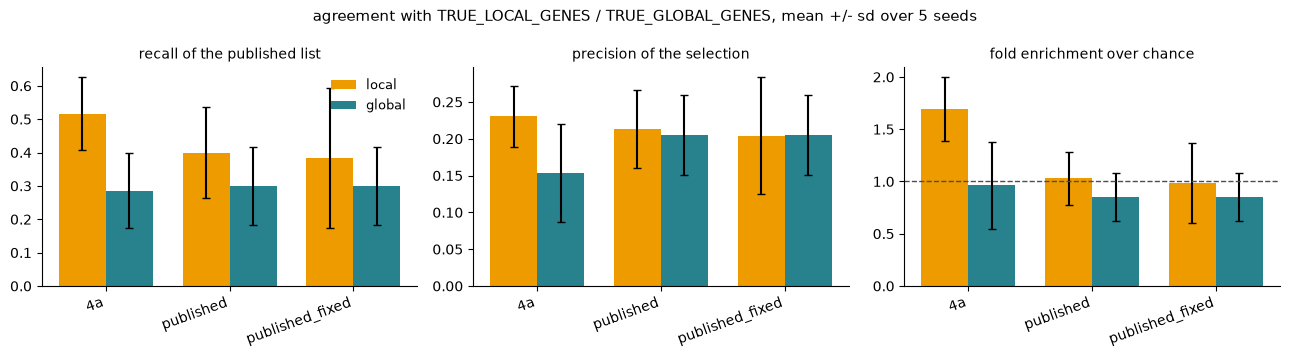

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
plot_spec = [("recall", "recall of the published list"),
             ("precision", "precision of the selection"),
             ("fold", "fold enrichment over chance")]
x = np.arange(len(READOUTS))
width = 0.38
for ax, (col, title) in zip(axes, plot_spec):
    for i, which in enumerate(("local", "global")):
        vals = [SUMMARY.loc[(which, name), col] for name in READOUTS]
        errs = [PER_SEED[(name, which)][col].std() for name in READOUTS]
        ax.bar(x + (i - 0.5) * width, vals, width, yerr=errs, capsize=3,
               color=GROUP_COLORS[which], label=which)
    ax.set_xticks(x)
    ax.set_xticklabels(list(READOUTS), rotation=20, ha="right")
    ax.set_title(title, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
# chance is 1 on the fold panel and the per-read-out expected/n_true on the recall panel; only
# the former is a single line, so only the former gets one.
axes[2].axhline(1.0, color="0.3", lw=1, ls="--")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("agreement with TRUE_LOCAL_GENES / TRUE_GLOBAL_GENES, mean +/- sd over 5 seeds",
             fontsize=11)
fig.tight_layout()
plt.show()

### 5b. Which published genes are actually recovered

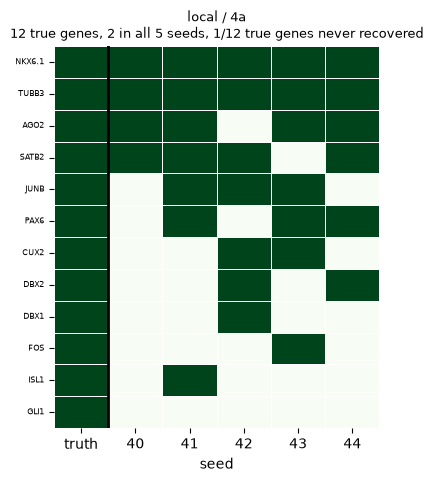

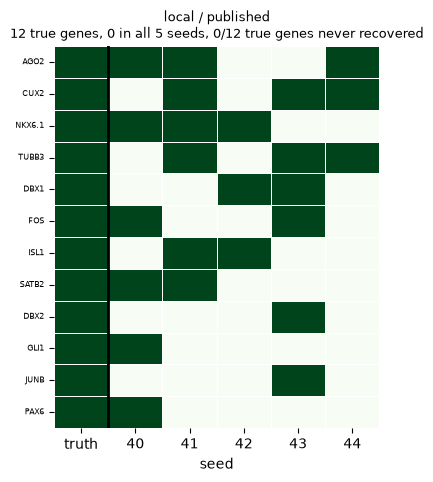

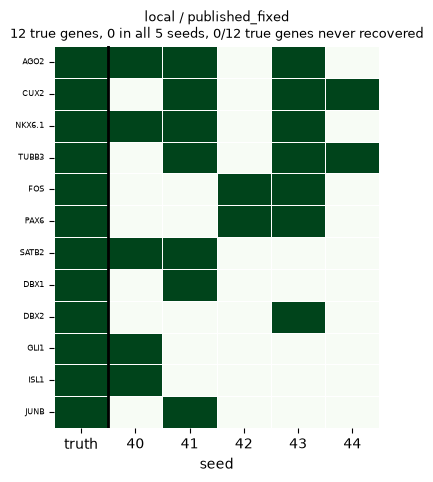

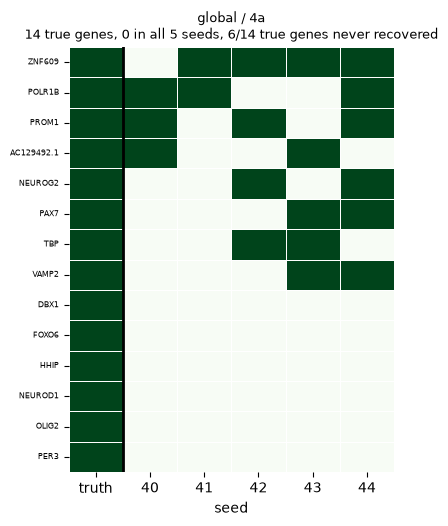

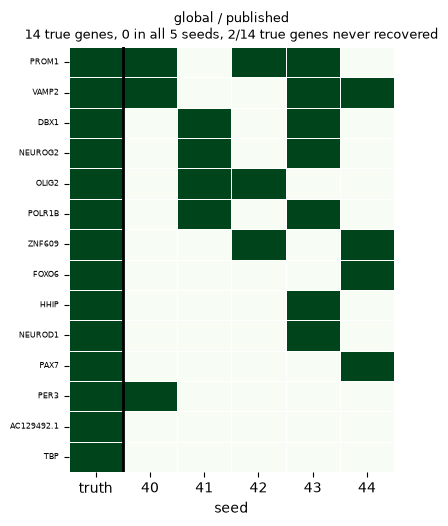

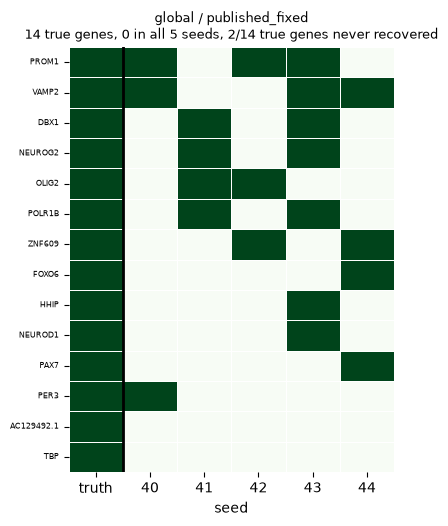

In [25]:
# Which of the published genes each read-out actually recovers, per seed. `only_truth=True` is
# the recall view: rows are the published genes and nothing else, so a gene never hit by any
# seed shows as an empty row.
for which in ("local", "global"):
    for name in READOUTS:
        fig, ax = plt.subplots(figsize=(4.2, 0.28 * len(TRUE[which]) + 1.6))
        plot_membership(TRUE[which], GENE_SETS[name][which], labels=SEEDS,
                        only_truth=True, ax=ax)
        ax.set_title(f"{which} / {name}\n" + ax.get_title(), fontsize=9)
        plt.show()

### 5c. Do the five seeds agree with each other?

In [26]:
# 4_a's own question, asked of each read-out: do the five seeds agree with EACH OTHER? That is
# separate from agreeing with the published list -- a read-out could be perfectly reproducible
# and reproducibly wrong.
#
# Read obs_mean against exp_mean, not against zero. On an 88-gene panel with 48-gene sets a
# 5-way intersection of ~1.5 genes is already what chance gives.
for name in READOUTS:
    sizes = {w: [len(df.index) for df in GENE_SETS[name][w]] for w in ("local", "global")}
    print("=" * 88)
    print(f"read-out {name}   set sizes  local {sizes['local']}   global {sizes['global']}")
    print(f"  pool {len(POOLS[name])} genes;  E|intersection of all 5| = "
          f"local {expected_intersection(sizes['local'], len(POOLS[name])):.3f}, "
          f"global {expected_intersection(sizes['global'], len(POOLS[name])):.3f}")
    for w in ("local", "global"):
        if min(sizes[w]) == 0:
            print(f"  {w}: at least one seed selected nothing -- skipping")
            continue
        overlap, common = overlap_matrix(GENE_SETS[name][w], labels=SEEDS)
        print(f"  --- {w} pairwise overlap ---")
        print(overlap.to_string())
        print(f"  {len(common)} genes in all {len(SEEDS)} seeds: {sorted(common)}")
        print(f"    of which published-{w}: "
              f"{sorted(set(common) & set(TRUE[w]))}")

read-out 4a   set sizes  local [25, 28, 26, 30, 25]   global [27, 26, 29, 25, 25]
  pool 88 genes;  E|intersection of all 5| = local 0.228, global 0.212
  --- local pairwise overlap ---
    40  41  42  43  44
40  25  16  15  18  15
41  16  28  16  18  15
42  15  16  26  17  14
43  18  18  17  30  15
44  15  15  14  15  25
  10 genes in all 5 seeds: ['Circ.CDR1', 'Circ.RMST', 'GLI2', 'MAP2', 'NKX6.1', 'PROM1', 'PTPRZ1', 'SOX2', 'TUBB3', 'ZNF609']
    of which published-local: ['NKX6.1', 'TUBB3']
  --- global pairwise overlap ---
    40  41  42  43  44
40  27  14  18  14  14
41  14  26  16  14  15
42  18  16  29  15  17
43  14  14  15  25  17
44  14  15  17  17  25
  8 genes in all 5 seeds: ['Circ.CDR1', 'Circ.RMST', 'MAP2', 'PTCH1', 'PTPRZ1', 'SOX2', 'STMN2', 'TUBB3']
    of which published-global: []
read-out published   set sizes  local [22, 25, 14, 29, 23]   global [13, 15, 19, 30, 29]
  pool 58 genes;  E|intersection of all 5| = local 0.454, global 0.285
  --- local pairwise overlap

======================================== 4a ========================================


======================================== published ========================================


======================================== published_fixed ========================================


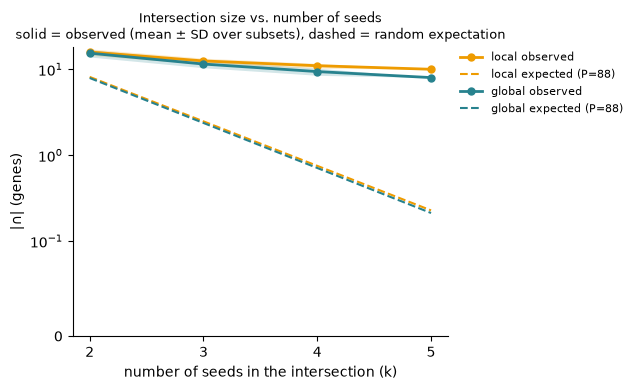

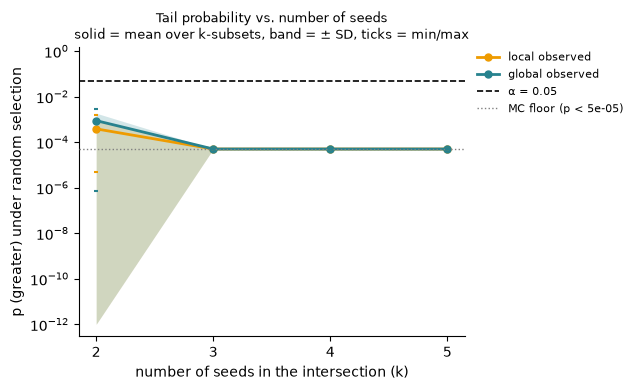

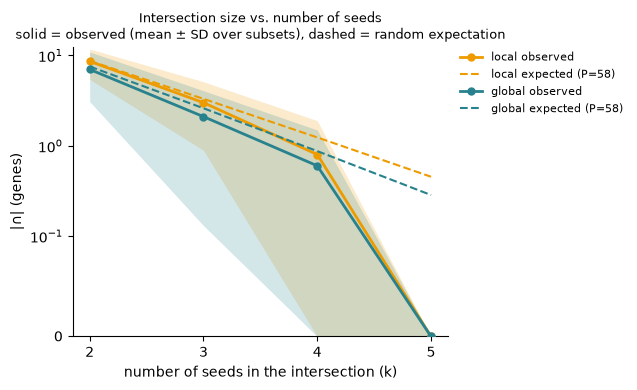

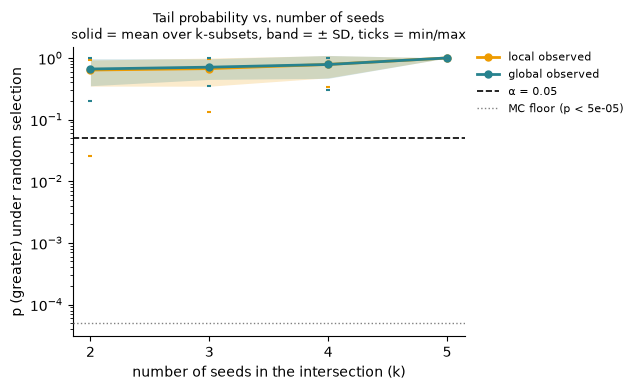

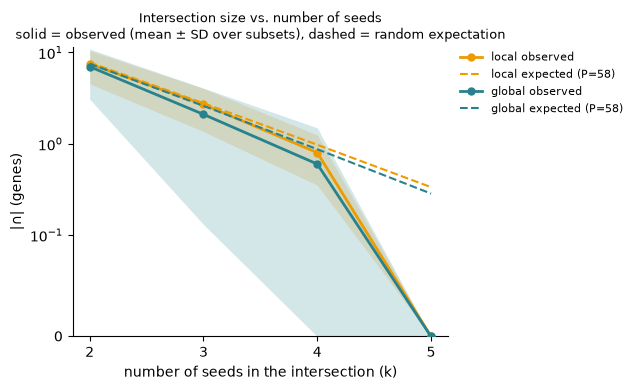

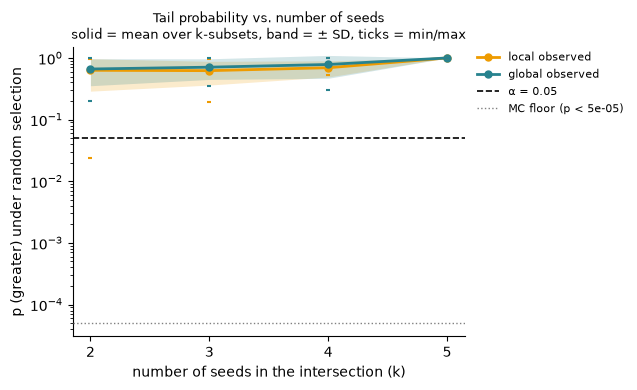

In [27]:
for name in READOUTS:
    if any(len(df.index) == 0 for w in ("local", "global") for df in GENE_SETS[name][w]):
        print(f"{name}: an empty selection makes the k-subset curves undefined -- skipped")
        continue
    print("=" * 40, name, "=" * 40)
    plot_intersection_by_k(
        {"local": GENE_SETS[name]["local"], "global": GENE_SETS[name]["global"]},
        pool=len(POOLS[name]), log=True,
    )
    plot_tail_prob_by_k(
        {"local": GENE_SETS[name]["local"], "global": GENE_SETS[name]["global"]},
        pool=len(POOLS[name]),
    )

In [28]:
# Which genes both decoders pick up, per seed. The local/global split is only interpretable
# within one model -- pooling it over seeds would mix five different latent bases.
for name in READOUTS:
    print("=" * 88, f"\nread-out {name}")
    for i, seed in enumerate(SEEDS):
        split = local_global_split(GENE_SETS[name]["local"][i], GENE_SETS[name]["global"][i])
        print(f"  seed {seed}")
        for k, v in split.items():
            print(f"    {k:14s} ({len(v):2d}): {v}")

read-out 4a
  seed 40
    shared         (12): ['STMN2', 'AGO2', 'NKX6.1', 'Circ.CDR1', 'Circ.RMST', 'PTPRZ1', 'PTCH1', 'MAP2', 'PROM1', 'TUBB3', 'SOX2', 'GLI3']
    unique_local   (13): ['BMP4', 'EOMES', 'FZD10', 'GLI2', 'MSX2', 'NEUROG2', 'OTP', 'OTX2', 'PAX7', 'SATB2', 'SNCA', 'ZNF609', 'ZSWIM8']
    unique_global  (15): ['AC129492.1', 'ARC', 'CDR1', 'CUX2', 'HES6', 'HPRT1', 'IRX3', 'JUN', 'LUM', 'MYRIP', 'NKX6.2', 'NR4A3', 'OIP5.AS1', 'POLR1B', 'SMO']
  seed 41
    shared         (14): ['ZSWIM8', 'GLI3', 'TUBB3', 'AGO2', 'NKX6.1', 'MAP2', 'Circ.RMST', 'PTPRZ1', 'PAX6', 'STMN2', 'MNX1', 'Circ.CDR1', 'ZNF609', 'SOX2']
    unique_local   (14): ['AC129492.1', 'AQP4', 'GAD1', 'GLI2', 'IRX3', 'ISL1', 'JUNB', 'NEUROD1', 'PAX7', 'PROM1', 'SATB2', 'SMO', 'TBP', 'VAMP2']
    unique_global  (12): ['CALB1', 'EYA4', 'FOS', 'FOXA1', 'JUN', 'KLF13', 'MSX2', 'MYRIP', 'NKX2.2', 'PER2', 'POLR1B', 'PTCH1']
  seed 42
    shared         (17): ['STMN2', 'PTPRZ1', 'PROM1', 'NEUROG2', 'ZNF609', 'TUBB3', '

### 5d. Training config vs read-out, crossed

In [29]:
# Was it the TRAINING config or the READ-OUT that moved the numbers? 4_a's 300-epoch cell arm
# (ze40fzaz) is the matched control -- same masking, same architecture, same five seeds, only
# n_epochs differs -- so running BOTH read-outs on BOTH arms crosses the two axes.
#
# This re-infers the ze40fzaz models into a separate AnnData. It is the expensive cell in the
# notebook (five more model loads and forward passes); set RUN_CROSS = False to skip it and read
# only the read-out axis above.
RUN_CROSS = True

CONTROL_MODELS_DIR = Path(BASE_DIR_PROJECT) / "results" / "legnini23_revision" / "seed_stability_cell"
CONTROL_RESULTS_DIR = Path(BASE_DIR_PROJECT) / "results" / DATA / "rec_seed_stablity_cell"

In [30]:
if RUN_CROSS and CONTROL_MODELS_DIR.exists():
    # Its own AnnData: run_seed_inference writes f"{seed}_..." keys, and the seeds are the same
    # five integers in both arms, so sharing one object would have the control silently overwrite
    # this arm's embeddings.
    adata_ctrl = adata.copy()

    def _seed_keys(mapping):
        # isinstance(k, str) is not defensive padding: anndata 0.13 yields a None key from
        # adata.layers, standing for .X, and `None.startswith` is an AttributeError.
        return [k for k in mapping
                if isinstance(k, str) and any(k.startswith(f"{s}_") for s in SEEDS)]

    for k in _seed_keys(adata_ctrl.obsm):
        del adata_ctrl.obsm[k]
    for k in _seed_keys(adata_ctrl.layers):
        del adata_ctrl.layers[k]

    # ze40fzaz pinned only optim.n_epochs (300) and model.save on top of the registry defaults.
    build_cfg_ctrl = partial(
        _build_cfg, DATASET, TASK, REGISTRY,
        models_dir=CONTROL_MODELS_DIR, overrides={"optim.n_epochs": 300},
    )
    adata_ctrl, models_ctrl, _, _, performance_ctrl = run_seed_inference(
        adata_ctrl, SEEDS, build_cfg_ctrl, CONTROL_MODELS_DIR, CONTROL_RESULTS_DIR,
        y_true=y_true, repro_seed=40, verbose=False,
    )

    CTRL_SETS = {}
    for name, kw in READOUTS.items():
        loc, glob, _ = collect_gene_sets(
            adata_ctrl, models_ctrl, SEEDS, layer_key=LAYER_KEY,
            allow_empty=True, plot=False, verbose=False, **kw,
        )
        CTRL_SETS[name] = {"local": loc, "global": glob}

    rows = []
    for arm, sets_ in [("sara_cfg (100 ep)", GENE_SETS), ("4a cell arm (300 ep)", CTRL_SETS)]:
        for name in READOUTS:
            for which in ("local", "global"):
                tab = recovery(sets_[name][which], TRUE[which], POOLS[name], SEEDS)
                rows.append({"arm": arm, "read_out": name, "component": which,
                             "n_selected": tab["n_selected"].mean(),
                             "n_hit": tab["n_hit"].mean(),
                             "recall": tab["recall"].mean(),
                             "fold": tab["fold"].mean(),
                             "p_median": tab["p"].median()})
    CROSS = pd.DataFrame(rows).set_index(["component", "read_out", "arm"]).sort_index()
    print(CROSS.to_string(float_format=lambda v: f"{v:.3f}"))
else:
    CROSS = None
    print("skipped (RUN_CROSS is False, or the ze40fzaz checkpoints are not on disk)")

Loading model from /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/legnini23_revision/seed_stability_cell/dual_legnini23_regr_node_40_GCN_self-attn-transformer_model.pt
Unclear checkpoint format. Attempting remapping anyway.
State dict remapping applied. Source detected: unknown
Load GEX from .layers/log1p_norm
INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


...

INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


                                                n_selected  n_hit  recall  fold  p_median
component read_out        arm                                                            
global    4a              4a cell arm (300 ep)      22.600  5.600   0.400 1.540     0.113
                          sara_cfg (100 ep)         26.400  4.000   0.286 0.963     0.750
          published       4a cell arm (300 ep)      26.000  5.800   0.414 0.857     0.728
                          sara_cfg (100 ep)         21.200  4.200   0.300 0.851     0.676
          published_fixed 4a cell arm (300 ep)      26.000  5.800   0.414 0.857     0.728
                          sara_cfg (100 ep)         21.200  4.200   0.300 0.851     0.676
local     4a              4a cell arm (300 ep)      24.200  5.400   0.450 1.639     0.095
                          sara_cfg (100 ep)         26.800  6.200   0.517 1.690     0.060
          published       4a cell arm (300 ep)      31.000  6.200   0.517 0.966     0.691
          

## 6. Why the published checkpoint cannot be the reference point

Everything above reproduces the published *configuration*. The obvious control would be the
published *checkpoint* -- Sara's seed-44 model is still on disk at
`/lustre/groups/ml01/workspace/sara.jimenez/InterScale/results/legnini23/model_dual_decoder/`,
and it carries the `MASK_VALUE = 0` fill that no yaml can restore.

It does not load, and not for a fixable reason: **the local GCN's architecture has changed since
that checkpoint was written** (2026-01). The current `module/local_modules/GCN.py` adds a
projected residual branch (`input_proj` + `input_norm`) and a `LayerNorm` after every graph
convolution; the checkpoint has neither, so its `layers.3` is the current model's `layers.4` and
eight parameter tensors have no counterpart. `BaseModel.load` refuses this rather than filling
the gaps with random initialisation -- correctly, because a partially initialised local encoder
feeds the global module too, so *both* embeddings and therefore every loading in this notebook
would be silently wrong.

The cell below prints the mismatch rather than asserting it, so the claim stays checkable. Note
this also means the `MASK_VALUE` question cannot be settled by loading -- only by retraining with
the old fill, which is a code change, not a config one.

In [31]:
import contextlib
import torch

SARA_DIR = Path("/lustre/groups/ml01/workspace/sara.jimenez/InterScale/results/legnini23/model_dual_decoder")
# NOTE the trailing underscore and the MISSING "model": BaseModel.load appends
# SAVE_KEYS.MODEL_FNAME ("model.pt", falling back to "model.ckpt") to whatever is passed here.
# Gene_loadings_analysis.ipynb passes the full "..._model" because load() did not append back
# then; copying that string now asks for "..._modelmodel.ckpt".
SARA_MODEL = "dual_legnini23_regr_node_44_GCN_self-attn-transformer_"


@contextlib.contextmanager
def _trusted_torch_load():
    """torch.load with weights_only=False, for the duration of the block.

    torch 2.6 flipped that default to True, and this 2026-01 checkpoint pickles a numpy scalar
    in its lightning metadata, so the default unpickler refuses to read it at all.
    BaseModel.load does not expose the flag. weights_only=False executes arbitrary pickled code,
    which is only acceptable because this file is ours. The seed_stability checkpoints above do
    not need it -- a newer lightning wrote them and stores no numpy scalars.
    """
    orig = torch.load
    torch.load = lambda *a, **k: orig(*a, **{**k, "weights_only": False})
    try:
        yield
    finally:
        torch.load = orig


if SARA_DIR.exists():
    adata_sara = adata.copy()
    cfg_sara = build_cfg(44)   # her seed, and the config this whole notebook pins

    interscale.model.CombinedModel._setup_anndata(
        adata=adata_sara,
        prediction_task=cfg_sara.dataset.prediction_task,
        layer_key=cfg_sara.dataset.layer_key,
        sample_key_list=cfg_sara.dataset.sample_key,
        prediction_obs=cfg_sara.dataset.prediction_obs,
        view_registry=False,
    )
    set_full_reproducibility(42)   # what Gene_loadings_analysis.ipynb sets
    try:
        with _trusted_torch_load():
            model_sara = interscale.model.CombinedModel.load(
                str(SARA_DIR), adata_sara, cfg_sara, model_name=SARA_MODEL,
                local_component=True, global_component=True,
            )
        print("loaded -- the architectures now agree, so this section can be revisited")
    except RuntimeError as exc:
        model_sara = None
        print(exc)

    # The same thing stated structurally: which module the mismatch is in. The GLOBAL side is
    # untouched -- it is only the local GCN that was rewritten -- but a CombinedModel feeds the
    # local embedding INTO the global module, so a broken local encoder is not a local problem.
    with _trusted_torch_load():
        ckpt = torch.load(SARA_DIR / f"{SARA_MODEL}model.ckpt", map_location="cpu")["state_dict"]
    ckpt_keys = {k.replace("module.", "", 1) for k in ckpt}
    model_keys = set(interscale.model.CombinedModel(adata_sara, cfg_sara).module.state_dict())
    for label, keys in [("only in the checkpoint", ckpt_keys - model_keys),
                        ("only in today's model", model_keys - ckpt_keys)]:
        print(f"\n{label} ({len(keys)}):")
        for k in sorted(keys):
            print("   ", k)
else:
    model_sara = None
    print(f"not readable: {SARA_DIR}")

Loading model from /lustre/groups/ml01/workspace/sara.jimenez/InterScale/results/legnini23/model_dual_decoder/dual_legnini23_regr_node_44_GCN_self-attn-transformer_model.pt
Try with .ckpt extension.
Unclear checkpoint format. Attempting remapping anyway.
State dict remapping applied. Source detected: unknown
Checkpoint does not match the model this cfg builds, so the mismatched tensors would keep their random initialisation and the model would be silently wrong.
  missing from the checkpoint (left random): ['local_module.input_proj.weight', 'local_module.input_proj.bias', 'local_module.input_norm.weight', 'local_module.input_norm.bias', 'local_module.layers.1.weight', 'local_module.layers.1.bias', 'local_module.layers.4.bias', 'local_module.layers.4.lin.weight']
  present in the checkpoint but not in the model: ['local_module.layers.3.bias', 'local_module.layers.3.lin.weight']
  checkpoint: /lustre/groups/ml01/workspace/sara.jimenez/InterScale/results/legnini23/model_dual_decoder/dual_

## 7. Verdict

In [32]:
# One-line answer, computed rather than asserted. Ranked on fold enrichment: recall alone
# rewards a read-out for selecting more genes, and "4a" selects up to half the panel.
for which in ("local", "global"):
    col = SUMMARY.loc[which, "fold"].dropna()
    base = SUMMARY.loc[(which, "4a")]
    if col.empty:
        print(f"{which:6s}: every read-out produced an empty or undefined selection")
        continue
    name = col.idxmax()
    row = SUMMARY.loc[(which, name)]
    print(
        f"{which:6s}: best read-out = {str(name):16s} "
        f"fold {row['fold']:.2f} (recall {row['recall']:.2f}, {row['n_selected']:.0f} genes)   "
        f"vs 4a fold {base['fold']:.2f} (recall {base['recall']:.2f}, {base['n_selected']:.0f} genes)"
    )

local : best read-out = 4a               fold 1.69 (recall 0.52, 27 genes)   vs 4a fold 1.69 (recall 0.52, 27 genes)
global: best read-out = 4a               fold 0.96 (recall 0.29, 26 genes)   vs 4a fold 0.96 (recall 0.29, 26 genes)
